<a href="https://colab.research.google.com/github/Kellia855/pneumonia_project/blob/main/pneumonia_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pneumonia Detection from Chest X-Rays: End-to-End ML Pipeline

This notebook presents an end-to-end machine learning pipeline for pneumonia detection from chest X-ray images. It builds a deep learning classifier that predicts whether a chest X-ray is NORMAL or shows signs of PNEUMONIA, extending my earlier COPD detection project from tabular survey data to medical image data within the same healthcare domain, with the aim of supporting early detection of respiratory conditions. The notebook covers the full machine learning cycle: data acquisition from the Kaggle Chest X-Ray Images (Pneumonia) dataset, cleaning and duplicate removal, a stratified train/validation/test split with a held-out batch for retraining, exploratory visualizations with interpretations, and preprocessing with augmentation and class weighting to handle class imbalance. It then trains and compares a baseline convolutional neural network with a MobileNetV2 transfer learning model, evaluates them using accuracy, precision, recall, F1-score, ROC-AUC and a confusion matrix, and provides a single-image prediction function and a retraining function. The best model is saved for deployment through an API and web interface, where users can predict on new X-rays, upload new data and trigger retraining.

**Dataset source:** https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia

## 1. Setup

To import the libraries, fix random seeds so every run gives the same splits and results and mount Google Drive, where the Kaggle dataset is stored.

In [2]:
import os, random, shutil, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_theme(style="whitegrid")
print("TensorFlow:", tf.__version__)

from google.colab import drive
drive.mount("/content/drive")

TensorFlow: 2.21.0
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Data Acquisition

### 2.1 Configuration

All paths and key settings live in one place so they can be changed without hunting through the notebook.

- `DRIVE_DATA_DIR`: the Drive folder that holds the downloaded Kaggle dataset.
- `WORK_DIR`: a working copy on Colab's local disk. Reading thousands of small images from Drive is slow, so we copy the data once and train from local disk.
- `NEW_DATA_PER_CLASS`: images per class set aside as the **"new data" batch** that we upload through the UI later to demonstrate retraining.

In [3]:
DRIVE_DATA_DIR = Path("/content/drive/MyDrive/pneumonia_project/chest_xray")

WORK_DIR = Path("/content/pneumonia_project")
DATA_DIR = WORK_DIR / "data"
MODELS_DIR = WORK_DIR / "models"
for d in (DATA_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

CLASSES = ["NORMAL", "PNEUMONIA"]
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NEW_DATA_PER_CLASS = 200     # held back for the retraining
VAL_FRAC, TEST_FRAC = 0.15, 0.15

# Kaggle zips often nest the data one level deeper (chest_xray/chest_xray). Handle that.
if not (DRIVE_DATA_DIR / "train").exists() and (DRIVE_DATA_DIR / "chest_xray" / "train").exists():
    DRIVE_DATA_DIR = DRIVE_DATA_DIR / "chest_xray"
print("Reading from:", DRIVE_DATA_DIR)
print("Folders found:", [p.name for p in DRIVE_DATA_DIR.iterdir()])

Reading from: /content/drive/MyDrive/pneumonia_project/chest_xray
Folders found: ['__MACOSX', 'train', 'test', 'val', 'chest_xray']


### 2.2 Build an inventory of every image

Instead of working with folders directly, we build a **DataFrame with one row per image** (file path, label, original split). Everything later (cleaning, splitting, plotting) becomes simple table operations and the table can be saved as a manifest.

In [4]:
VALID_EXT = {".jpg", ".jpeg", ".png"}
rows = []
for split in ["train", "val", "test"]:
    for label in CLASSES:
        folder = DRIVE_DATA_DIR / split / label
        if not folder.exists():
            print("Missing folder:", folder)
            continue
        for f in folder.iterdir():
            if f.suffix.lower() in VALID_EXT and not f.name.startswith("."):
                rows.append({"path": str(f), "label": label, "orig_split": split})

df = pd.DataFrame(rows)
print("Total images found:", len(df))
display(pd.crosstab(df["orig_split"], df["label"], margins=True))

Total images found: 5856


label,NORMAL,PNEUMONIA,All
orig_split,,,
test,234,390,624
train,1341,3875,5216
val,8,8,16
All,1583,4273,5856


### Interpretation:
- The original download holds roughly **5,800 images**: about 5,200 train, about 620 test, and only **16 in `val`**.
- **PNEUMONIA outnumbers NORMAL by roughly 3 to 1** in the training split.
- The 16-image validation set is far too small to tune a model reliably, so we will **re-split the data ourselves**

## 3. Data Cleaning

### 3.1 Integrity check and image metadata

Before training, we make sure every file is a readable image and record each image's **width, height, colour mode and file size**. This catches corrupt files and the metadata is reused later for visualizations.

In [5]:
def inspect_image(path):
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            w, h = im.size
            return w, h, im.mode, os.path.getsize(path), True
    except Exception:
        return None, None, None, None, False

meta = df["path"].apply(inspect_image)
df[["width", "height", "mode", "file_bytes", "readable"]] = pd.DataFrame(meta.tolist(), index=df.index)

print("Unreadable files:", (~df["readable"]).sum())
print("\nColour modes:")
print(df["mode"].value_counts(dropna=False))
df = df[df["readable"]].copy()
print("\nImages after removing unreadable files:", len(df))

Unreadable files: 0

Colour modes:
mode
L      5573
RGB     283
Name: count, dtype: int64

Images after removing unreadable files: 5856


There are no **Unreadable files**. Any corrupt images are dropped here so they cannot crash training later. X-rays are inherently grayscale, but files may be stored as `L` (grayscale) or `RGB`. Mixed modes are a common cause of shape errors, so in preprocessing we convert everything to **3-channel RGB**

### 3.2 Duplicate detection

Duplicate images are dangerous: if the same X-ray lands in both train and test, the model is "tested" on something it has already seen and the metrics look better than they really are (**data leakage**). We hash each file's bytes (MD5) to find exact duplicates and keep one copy of each.

In [6]:
def file_md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while True:
            block = f.read(chunk)
            if not block:
                break
            h.update(block)
    return h.hexdigest()

df["md5"] = df["path"].apply(file_md5)
dup_mask = df.duplicated(subset="md5", keep="first")
print("Exact duplicate files:", dup_mask.sum())

# Same hash but different labels would be a labelling conflict
conflicts = df.groupby("md5")["label"].nunique()
print("Hashes with conflicting labels:", (conflicts > 1).sum())

df = df[~dup_mask].reset_index(drop=True)
print("Images after de-duplication:", len(df))
display(df["label"].value_counts().to_frame("count"))

Exact duplicate files: 32
Hashes with conflicting labels: 0
Images after de-duplication: 5824


,count
label,
PNEUMONIA,4245
NORMAL,1579


### Interpretation
The duplicate check found 32 exact duplicate files and removed them, leaving 5,824 images. No images shared a hash with a different label (0 conflicting labels), so there are no ambiguous or mislabelled duplicates. The cleaned dataset holds 4,245 PNEUMONIA and 1,579 NORMAL images, a ratio of about 2.7 to 1, so the class imbalance remains. Cleaning removed under 1% of the data which keeps the dataset large enough for transfer learning and protects the evaluation from data leakage.

## 4. Splitting the Data

### 4.1 Hold out a "new data" batch and create train / val / test

Two decisions are made here:

1. **New-data batch for retraining.** We set aside `NEW_DATA_PER_CLASS` images per class (balanced) that the model will never see during initial training. During the demo, we upload these through the UI and trigger retraining, so retraining is shown on genuinely unseen images.
2. **Stratified 70 / 15 / 15 split** of the remaining images. The original `train/val/test` folders are pooled and re-split because the original validation set has only 16 images. **Stratification** keeps the NORMAL:PNEUMONIA ratio the same in each split, and the fixed seed makes it reproducible.

In [7]:
print(df["label"].value_counts())
print(df["orig_split"].value_counts())
print("Total:", len(df))

label
PNEUMONIA    4245
NORMAL       1579
Name: count, dtype: int64
orig_split
train    5190
test      618
val        16
Name: count, dtype: int64
Total: 5824


In [8]:
# balanced new-data batch
new_parts = []
for label in CLASSES:
    sub = df[df["label"] == label]
    new_parts.append(sub.sample(n=NEW_DATA_PER_CLASS, random_state=SEED))
new_df = pd.concat(new_parts)
rest = df.drop(new_df.index)

# stratified train / val / test on the rest
train_df, temp_df = train_test_split(
    rest, test_size=VAL_FRAC + TEST_FRAC, stratify=rest["label"], random_state=SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC), stratify=temp_df["label"], random_state=SEED)

new_df = new_df.assign(split="new_data")
train_df = train_df.assign(split="train")
val_df = val_df.assign(split="val")
test_df = test_df.assign(split="test")
full = pd.concat([train_df, val_df, test_df, new_df]).reset_index(drop=True)

display(pd.crosstab(full["split"], full["label"], margins=True))
display(pd.crosstab(full["split"], full["label"], normalize="index").round(3))

label,NORMAL,PNEUMONIA,All
split,,,
new_data,200,200,400
test,207,607,814
train,965,2831,3796
val,207,607,814
All,1579,4245,5824


label,NORMAL,PNEUMONIA
split,,
new_data,0.500,0.500
test,0.254,0.746
train,0.254,0.746
val,0.254,0.746


### Interpretation
The 5,824 cleaned images were split into 3,796 for training (65%), 814 for validation (14%), 814 for testing (14%) and a 400-image new-data batch (7%) held back for the retraining demo. The three main splits have identical class proportions of about 25.4% NORMAL and 74.6% PNEUMONIA, so the stratified split worked and the splits are comparable. The new_data batch is exactly balanced at 200 images per class. It was drawn out first, so the 70/15/15 ratios apply to the remaining 5,424 images.

### 4.2 Copy images into the project folder structure

The files are copied  into `data/<split>/<CLASS>/` on local disk. A manifest CSV records which file went to which split, so the split can be audited.

In [9]:
from tqdm.auto import tqdm

for split in ["train", "val", "test", "new_data"]:
    for label in CLASSES:
        (DATA_DIR / split / label).mkdir(parents=True, exist_ok=True)

for _, r in tqdm(full.iterrows(), total=len(full)):
    src = Path(r["path"])
    dst = DATA_DIR / r["split"] / r["label"] / f"{r['md5'][:10]}_{src.name}"
    if not dst.exists():
        shutil.copy2(src, dst)

full["local_path"] = [str(DATA_DIR / r.split / r.label / f"{r.md5[:10]}_{Path(r.path).name}")
                      for r in full.itertuples()]
full.to_csv(WORK_DIR / "data_manifest.csv", index=False)

for split in ["train", "val", "test", "new_data"]:
    n = sum(len(list((DATA_DIR / split / c).glob("*"))) for c in CLASSES)
    print(f"{split:9s}: {n} files")

  0%|          | 0/5824 [00:00<?, ?it/s]

train    : 3796 files
val      : 814 files
test     : 814 files
new_data : 400 files


## 5. Data Visualization and Interpretation

We look at **four** features: class balance, visual appearance, image dimensions, and pixel intensity (brightness). For each, the question is not just "what does it look like" but **"what does it mean for the model?"**

### 5.1 Feature 1: Class distribution

Class balance decides which metrics are trustworthy. If one class dominates, a model can score high accuracy by simply predicting the majority class. We plot class counts for the full cleaned dataset and for each split.

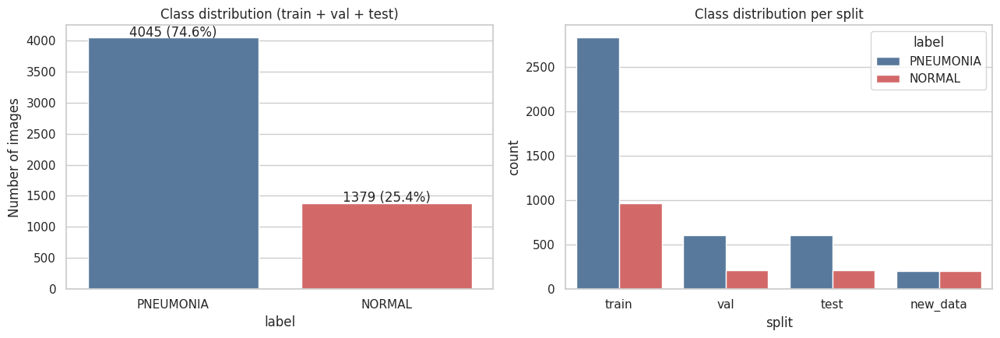

PNEUMONIA : NORMAL ratio = 2.93 : 1


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

counts = full[full["split"] != "new_data"]["label"].value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=axes[0], palette=["#4C78A8", "#E45756"])
axes[0].set_title("Class distribution (train + val + test)")
axes[0].set_ylabel("Number of images")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 20, f"{v} ({v / counts.sum():.1%})", ha="center")

sns.countplot(data=full, x="split", hue="label", order=["train", "val", "test", "new_data"],
              palette=["#4C78A8", "#E45756"], ax=axes[1])
axes[1].set_title("Class distribution per split")
plt.tight_layout()
plt.show()

ratio = counts["PNEUMONIA"] / counts["NORMAL"]
print(f"PNEUMONIA : NORMAL ratio = {ratio:.2f} : 1")

### Interpretation
The class distribution plot covers the 5,424 images in train, validation and test (the balanced new_data batch is excluded). It shows a clear imbalance: 4,045 PNEUMONIA (74.6%) versus 1,379 NORMAL (25.4%), a ratio of 2.93 : 1. The per-split plot shows the same roughly 3:1 shape in train, validation and test, so the stratified split worked, while new_data is balanced at 200 images per class. Because of this imbalance, a model that predicts PNEUMONIA for every image would score about 75% accuracy without detecting a single healthy patient. So the project uses class weights and judges the models on precision, recall, F1, ROC-AUC and the confusion matrix, with recall on PNEUMONIA as the priority metric

### 5.2 Feature 2: What the images actually look like

Plotting samples shows what the model has to learn. We display random images from each class in a grid, using a fixed seed so the grid is reproducible.

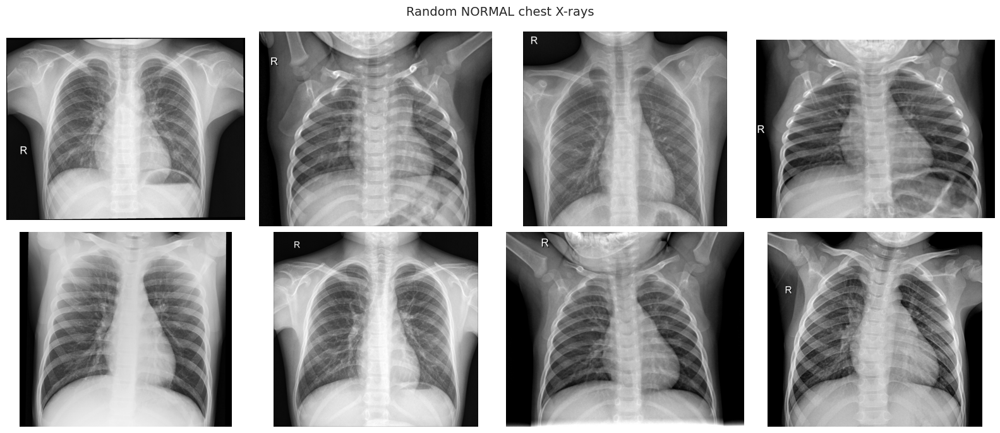

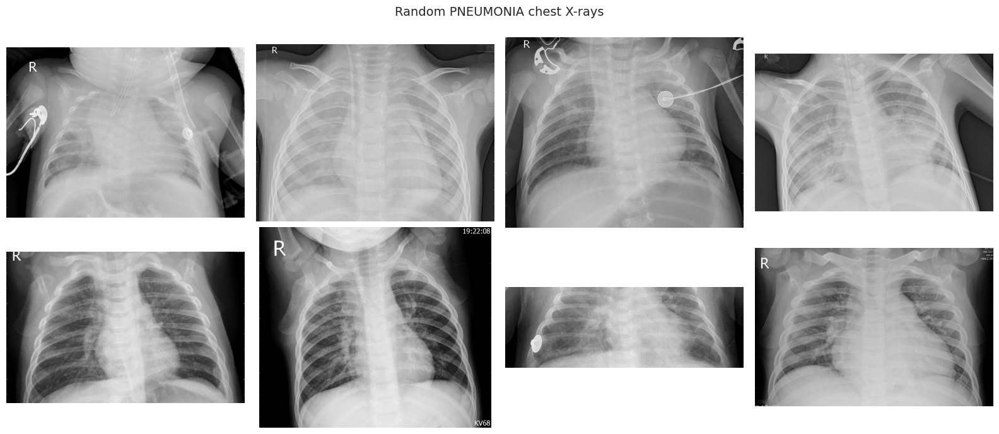

In [11]:
def show_samples(label, n=8, seed=SEED):
    sub = full[(full["split"] == "train") & (full["label"] == label)].sample(n, random_state=seed)
    fig, axes = plt.subplots(2, n // 2, figsize=(16, 7))
    for ax, p in zip(axes.ravel(), sub["local_path"]):
        ax.imshow(Image.open(p).convert("L"), cmap="gray")
        ax.axis("off")
    fig.suptitle(f"Random {label} chest X-rays", fontsize=14)
    plt.tight_layout()
    plt.show()

show_samples("NORMAL")
show_samples("PNEUMONIA")

### After the cell: interpretation
In the sample grid, NORMAL X-rays show dark, clear lung fields with sharp rib outlines and well-defined heart and diaphragm borders. Most PNEUMONIA X-rays look hazier, with greyer lung fields, less distinct ribs and patchy whitish areas, although a couple (bottom row) look almost as clear as normal ones, which shows why the task is hard. The two classes also differ in how the images look. NORMAL images tend to be larger, wider frames showing more of the neck and shoulders, and the chests look bigger, while many PNEUMONIA images are tighter crops of smaller chests, and one is a very wide, thin strip. Three of the eight PNEUMONIA images contain monitoring leads, wires or devices, a timestamp appears on one, and letter markers (“R”) appear in both classes. No obvious leads or devices are visible in the NORMAL sample. A model could latch onto these non-medical cues (image framing, patient size, equipment) instead of real lung pathology, which is why augmentation is used and why very high accuracy needs careful interpretation.

### 5.3 Feature 3: Image dimensions

#### Before the cell
Images come from different machines and hospitals and have **different resolutions**. We plot width and height per class. Systematic size differences between classes could let a model "cheat" by recognising size rather than disease. It also tells us what to resize to.

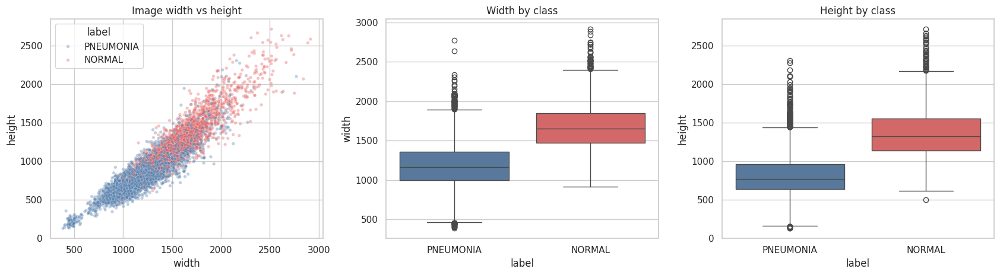

label         NORMAL  PNEUMONIA
width  count  1579.0     4245.0
       mean   1686.0     1194.0
       std     304.0      285.0
       min     912.0      384.0
       25%    1472.0     1000.0
       50%    1654.0     1160.0
       75%    1848.0     1360.0
       max    2916.0     2772.0
height count  1579.0     4245.0
       mean   1378.0      818.0
       std     341.0      271.0
       min     496.0      127.0
       25%    1140.0      640.0
       50%    1323.0      768.0
       75%    1554.0      960.0
       max    2713.0     2304.0

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

sns.scatterplot(data=full, x="width", y="height", hue="label", alpha=0.35, s=15,
                palette=["#4C78A8", "#E45756"], ax=axes[0])
axes[0].set_title("Image width vs height")

sns.boxplot(data=full, x="label", y="width", palette=["#4C78A8", "#E45756"], ax=axes[1])
axes[1].set_title("Width by class")

sns.boxplot(data=full, x="label", y="height", palette=["#4C78A8", "#E45756"], ax=axes[2])
axes[2].set_title("Height by class")
plt.tight_layout()
plt.show()

display(full.groupby("label")[["width", "height"]].describe().round(0).T)

### Interpretation
The two classes differ clearly in size. NORMAL images are much larger, with a median width of 1,654 px and median height of 1,323 px, against 1,160 px and 768 px for PNEUMONIA. The boxplots show that the middle 50% of the two classes don’t overlap at all, in width (1,472 to 1,848 px for NORMAL, 1,000 to 1,360 px for PNEUMONIA) or in height (1,140 to 1,554 px against 640 to 960 px). In the scatter plot the classes overlap only in a band of mid-sized images, and PNEUMONIA extends down to very small images (minimum 384 px wide and 127 px tall) while NORMAL starts at 912 px wide. Image size alone could therefore separate many cases, which makes it a likely dataset bias, and a high test score has to be read with that in mind.

### 5.4 Feature 4: Pixel intensity (brightness)

Pneumonia shows up as **whiter regions** in the lungs, so average brightness is a natural feature to compare between classes. We compute the mean pixel value of each image (after resizing to 224 x 224 grayscale for speed) on a sample of the training set, then plot its distribution per class, and also plot the **average image** of each class to see where the differences are located.

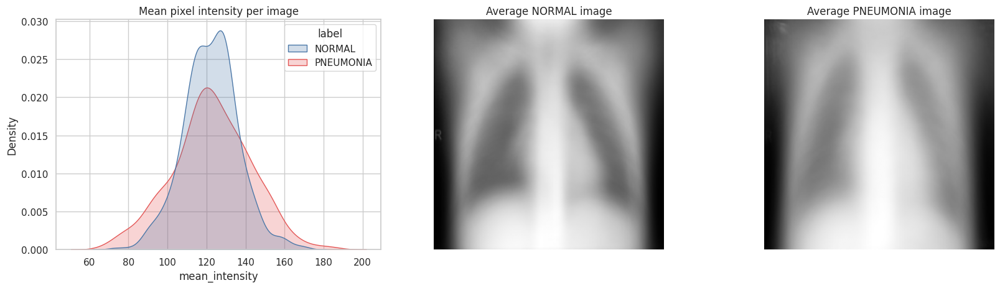

           count   mean   std   min    25%    50%    75%    max
label                                                          
NORMAL     600.0  122.2  13.9  73.3  113.5  122.4  130.6  169.7
PNEUMONIA  600.0  122.6  20.0  67.2  110.1  122.2  135.5  185.1


In [13]:
sample = (full[full["split"] == "train"]
          .groupby("label", group_keys=False)
          .apply(lambda g: g.sample(min(len(g), 600), random_state=SEED)))

def load_gray(p):
    return np.asarray(Image.open(p).convert("L").resize(IMG_SIZE), dtype=np.float32)

arrays = {lab: np.stack([load_gray(p) for p in sample[sample.label == lab]["local_path"]])
          for lab in CLASSES}

intensity = pd.DataFrame({
    "label": np.repeat(CLASSES, [len(arrays[c]) for c in CLASSES]),
    "mean_intensity": np.concatenate([arrays[c].mean(axis=(1, 2)) for c in CLASSES]),
})

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.kdeplot(data=intensity, x="mean_intensity", hue="label", fill=True,
            palette=["#4C78A8", "#E45756"], common_norm=False, ax=axes[0])
axes[0].set_title("Mean pixel intensity per image")
for ax, lab in zip(axes[1:], CLASSES):
    ax.imshow(arrays[lab].mean(axis=0), cmap="gray")
    ax.set_title(f"Average {lab} image")
    ax.axis("off")
plt.tight_layout()
plt.show()

print(intensity.groupby("label")["mean_intensity"].describe().round(1))

### Interpretation
Average brightness is virtually identical between the two classes (about 122 for both), so overall brightness is not a usable signal for telling them apart. The difference is in spread: PNEUMONIA images vary much more (standard deviation 20.0 vs 13.9, range 67 to 185 vs 73 to 170), probably because lung opacities make some scans much brighter or darker, and the two distributions overlap heavily, so a CNN has to learn spatial patterns, not overall brightness. The average images show where the classes differ: the NORMAL average has dark, well-defined lung fields against a bright central column, while the PNEUMONIA average is hazier, with greyer lung fields and lower contrast. Brightness and contrast also depend on scanner settings and exposure, and a faint “R” marker is visible in the NORMAL average, so a model could pick up non-medical cues, which is why brightness and contrast augmentation is used to reduce this risk.

### 5.5 Summary of what the exploration tells us

| Feature | Finding | Decision for modelling |
|---|---|---|
| Class balance | PNEUMONIA is about 3x NORMAL | Class weights, report recall / F1 / AUC, not just accuracy |
| Appearance | Pneumonia shows cloudy opacities, but cases overlap | Use a CNN with transfer learning, augmentation |
| Dimensions | Widely varying sizes, possible class-size bias | Resize all images to 224 x 224 identically in training and API |
| Brightness | Pneumonia tends to be brighter, with heavy overlap | Brightness/contrast augmentation to avoid shortcut learning |

## 6. Preprocessing Pipeline

### 6.1 Load the datasets with `tf.data`

We build input pipelines that read the images from `data/train`, `data/val` and `data/test`, resize them to 224 x 224 and batch them.


In [14]:
common = dict(
    labels="inferred",
    label_mode="binary",
    class_names=CLASSES,
    color_mode="rgb",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=SEED,
)

train_ds = tf.keras.utils.image_dataset_from_directory(DATA_DIR / "train", shuffle=True, **common)
val_ds   = tf.keras.utils.image_dataset_from_directory(DATA_DIR / "val",   shuffle=False, **common)
test_ds  = tf.keras.utils.image_dataset_from_directory(DATA_DIR / "test",  shuffle=False, **common)

print("Class order:", train_ds.class_names)
for images, labels in train_ds.take(1):
    print("Batch images:", images.shape, "| dtype:", images.dtype,
          "| pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))
    print("Batch labels:", labels.shape)

Found 3796 files belonging to 2 classes.
Found 814 files belonging to 2 classes.
Found 814 files belonging to 2 classes.
Class order: ['NORMAL', 'PNEUMONIA']
Batch images: (32, 224, 224, 3) | dtype: <dtype: 'float32'> | pixel range: 0.0 to 255.0
Batch labels: (32, 1)


### 6.2 Class weights

To compensate for the imbalance without throwing images away, we compute **class weights**. The minority class (NORMAL) gets a larger weight, so mistakes on it cost more during training.

In [15]:
train_labels = full[full["split"] == "train"]["label"].map({"NORMAL": 0, "PNEUMONIA": 1}).values
weights = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=train_labels)
class_weight = {0: float(weights[0]), 1: float(weights[1])}
print("Class weights:", class_weight)

Class weights: {0: 1.966839378238342, 1: 0.6704344754503709}


### Interpretation
Class weights were computed with the “balanced” method from the training labels, giving NORMAL a weight of 1.97 and PNEUMONIA 0.67. This makes a mistake on a NORMAL image count about three times as much as one on a PNEUMONIA image, which offsets the 3:1 imbalance without discarding any data. These weights are passed to model.fit() so the model cannot score well by predicting PNEUMONIA for everything.

### 6.3 Data augmentation

Augmentation creates slightly altered copies of training images on the fly, which reduces overfitting and makes the model robust to differences in positioning and exposure.

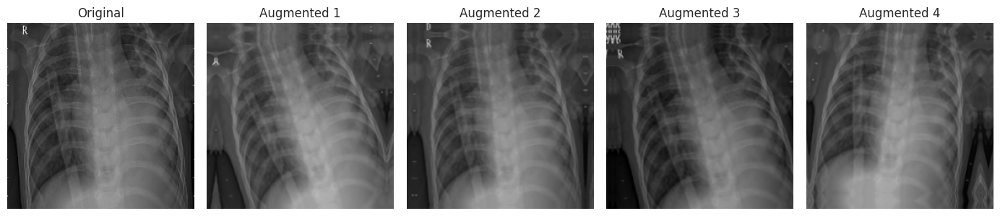

In [16]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
    tf.keras.layers.RandomBrightness(0.10, value_range=(0, 255)),
    tf.keras.layers.RandomContrast(0.10),
], name="data_augmentation")

# Visual check: the same training image augmented several times
for images, labels in train_ds.take(1):
    img = images[0]
    plt.figure(figsize=(14, 3.5))
    plt.subplot(1, 5, 1)
    plt.imshow(tf.cast(img, tf.uint8)); plt.title("Original"); plt.axis("off")
    for i in range(4):
        aug = data_augmentation(tf.expand_dims(img, 0), training=True)[0]
        plt.subplot(1, 5, i + 2)
        plt.imshow(tf.cast(tf.clip_by_value(aug, 0, 255), tf.uint8))
        plt.title(f"Augmented {i + 1}"); plt.axis("off")
    plt.tight_layout(); plt.show()

### Interpretation
The four augmented versions are still recognizable as the same chest X-ray, with small shifts, slight rotation and zoom, and changes in brightness and contrast. The ribs, spine and lung fields stay anatomically plausible, so the settings are safe to keep. The only side effect is at the edges, where shifted or rotated images are filled by reflecting nearby pixels, which leaves faint mirrored strips on some copies (for example augmented 1 and 4). This is minor at these strengths, but it is the reason not to increase the rotation, zoom or shift further.

### 6.4 Performance: cache and prefetch

`cache()` keeps decoded images in memory after the first epoch and `prefetch()` prepares the next batch while the GPU or CPU is busy with the current one. Together they remove the data-loading bottleneck and speed up training and retraining.

In [17]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)
print("Input pipelines ready.")

Input pipelines ready.


## 7. Save Progress and Next Steps

Colab's local disk is wiped when the runtime resets. We copy the manifest and the prepared `data/` folder back to Drive so the split does not have to be rebuilt.

In [18]:
BACKUP_DIR = Path("/content/drive/MyDrive/pneumonia_project")
BACKUP_DIR.mkdir(parents=True, exist_ok=True)
shutil.copy2(WORK_DIR / "data_manifest.csv", BACKUP_DIR / "data_manifest.csv")
print("Manifest backed up to:", BACKUP_DIR)

# Optional: back up the prepared data folder as well (can take a few minutes)
# shutil.copytree(DATA_DIR, BACKUP_DIR / "data", dirs_exist_ok=True)

Manifest backed up to: /content/drive/MyDrive/pneumonia_project


# PART 2: Modelling, Evaluation, Prediction and Retraining

**This part builds**

| Stage | Section |
|---|---|
| Model creation (baseline CNN and MobileNetV2 transfer learning) | 8, 9 |
| Model testing (all metrics, curves, error analysis) | 10 |
| Saving the model and its metadata | 11 |
| Single-image prediction function | 12 |
| Retraining trigger and retraining function | 13 |

## 8. Model 1: Baseline CNN (trained from scratch)

### 8.1 Shared helpers

We define the pieces both models share:

- `augment_ds()` applies the augmentation from Section 6.3 to a dataset **in the data pipeline**, with a fresh random transformation every epoch. This is a change from what Section 6.3 said (augmentation inside the model). Putting random layers inside the model made the `.h5` file unreliable: Keras could not save some of them (`RandomBrightness`), and a model reloaded from `.h5` could not be saved again, which breaks retraining. Applying augmentation in the pipeline gives the same training effect, and the saved model is a clean **inference-only** network (smaller, faster, and safe to reload and retrain).
- `get_metrics()` returns the metrics tracked during training: accuracy, precision, recall and AUC. Because of the class imbalance, recall and AUC matter more than accuracy.
- `get_callbacks()` adds **early stopping** (stop when validation loss stops improving and restore the best weights) and **learning-rate reduction** (cut the learning rate when progress stalls).
- `plot_history()` draws loss, accuracy and AUC curves for training vs validation, which is the main way to spot overfitting.

In [19]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve)
import json, datetime

print("GPU available:", tf.config.list_physical_devices("GPU"))

INPUT_SHAPE = IMG_SIZE + (3,)
L = tf.keras.layers

def augment_ds(ds):
    # data_augmentation is the Sequential block defined in Section 6.3
    return ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                  num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

def get_metrics():
    return [
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc"),
    ]

def get_callbacks(patience=4):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience,
                                         restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                             patience=2, min_lr=1e-7, verbose=1),
    ]

def merge_histories(*histories):
    out = {}
    for h in histories:
        for k, v in h.history.items():
            out.setdefault(k, []).extend(v)
    return out

def plot_history(h, title, finetune_start=None):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for ax, metric in zip(axes, ["loss", "accuracy", "auc"]):
        ax.plot(h[metric], label="train")
        ax.plot(h["val_" + metric], label="validation")
        if finetune_start is not None:
            ax.axvline(finetune_start - 0.5, color="gray", ls="--", label="fine-tuning starts")
        ax.set_title(metric)
        ax.set_xlabel("epoch")
        ax.legend()
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 8.2 Experiment tracking: TensorBoard and Weights & Biases

#### Before the cell
Keras does not keep a record of training runs: the `History` object lives only in memory and disappears when the Colab runtime restarts. We therefore log every run to two tools:

- **TensorBoard** writes logs to a local `logs/` folder (backed up to Drive in Section 13.5) and shows the training curves in an interactive viewer inside the notebook (Section 9.5).
- **Weights & Biases (W&B)** stores each run online, so runs can be compared across sessions. We log the training curves (every epoch), the evaluation results, the saved model as a versioned artifact, and the retraining runs.

**Login without typing a key:** the W&B API key is read from **Colab Secrets** (the key icon in the left sidebar). Add a secret named `WANDB_API_KEY`, paste your key from wandb.ai/authorize, and switch *Notebook access* on. The key never appears in the notebook. If the secret is missing, the notebook falls back to **offline mode** (runs are saved locally and can be uploaded later with `wandb sync`), so training still works.

In [20]:
import subprocess, sys
try:
    import wandb
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wandb"], check=True)
    import wandb
from wandb.integration.keras import WandbMetricsLogger

WANDB_PROJECT = "pneumonia-xray"
LOGS_DIR = WORK_DIR / "logs"
LOGS_DIR.mkdir(parents=True, exist_ok=True)

try:
    from google.colab import userdata
    os.environ["WANDB_API_KEY"] = userdata.get("WANDB_API_KEY")
    wandb.login()
    print("W&B: logged in using Colab Secrets.")
except Exception as e:
    os.environ["WANDB_MODE"] = "offline"
    print(f"W&B: no key found ({type(e).__name__}); running OFFLINE. Runs are stored locally.")

def wb_start(name, config=None, tags=None):
    return wandb.init(project=WANDB_PROJECT, name=name, config=config or {},
                      tags=tags or [], reinit=True)

def tracking_callbacks(name):
    tb_dir = LOGS_DIR / name
    tb_dir.mkdir(parents=True, exist_ok=True)
    return [tf.keras.callbacks.TensorBoard(log_dir=str(tb_dir)), WandbMetricsLogger()]

print("Project:", WANDB_PROJECT, "| TensorBoard logs:", LOGS_DIR)

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: k-kamikazi (k-kamikazi-african-leadership-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B: logged in using Colab Secrets.
Project: pneumonia-xray | TensorBoard logs: /content/pneumonia_project/logs


### After the cell
- `W&B: logged in using Colab Secrets.` means runs will appear in your W&B project `pneumonia-xray`. The OFFLINE message means the secret was not found or notebook access is off; fix that and re-run this cell if you want the online dashboard.
- Two helpers are now available: `wb_start()` opens a run, and `tracking_callbacks()` returns the TensorBoard and W&B callbacks that are added to `fit()` below.

### 8.3 Build the baseline CNN

#### Before the cell
The baseline is a small convolutional network trained **from scratch**. It gives us a reference point: if a pretrained model does not clearly beat it, the extra complexity would not be justified.

Architecture:
- `Rescaling(1/255)` to bring pixels into 0 to 1 (scaling is part of the model, so the API does not need its own scaling code). Augmentation is not part of the model; it is applied to the training data (Section 8.4).
- Four blocks of `Conv2D` (32, 64, 128, 128 filters) + `BatchNormalization` + `MaxPooling2D`. Early layers pick up edges and textures, deeper layers combine them into larger lung patterns.
- `GlobalAveragePooling2D` + `Dropout` + a small dense layer, ending in **one sigmoid unit** that outputs the probability of PNEUMONIA.

In [21]:
def build_baseline_cnn():
    inputs = tf.keras.Input(shape=INPUT_SHAPE)
    x = L.Rescaling(1.0 / 255)(inputs)
    for filters in (32, 64, 128, 128):
        x = L.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = L.BatchNormalization()(x)
        x = L.MaxPooling2D()(x)
    x = L.GlobalAveragePooling2D()(x)
    x = L.Dropout(0.4)(x)
    x = L.Dense(64, activation="relu")(x)
    x = L.Dropout(0.3)(x)
    outputs = L.Dense(1, activation="sigmoid")(x)
    return tf.keras.Model(inputs, outputs, name="baseline_cnn")

tf.keras.utils.set_random_seed(SEED)
baseline_model = build_baseline_cnn()
baseline_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                       loss="binary_crossentropy", metrics=get_metrics())
baseline_model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 250,561 (978.75 KB)

 Trainable params: 249,857 (976.00 KB)

 Non-trainable params: 704 (2.75 KB)

### After the cell
- The summary lists each layer and the parameter count (roughly a few hundred thousand parameters, small by deep learning standards, which keeps training and later retraining quick).
- The output shape of the last layer must be `(None, 1)`: a single probability per image.

### 8.4 Train the baseline

#### Before the cell
We train on the **augmented** training data (`train_aug`) with `class_weight` (from Section 6.2) so mistakes on the minority NORMAL class cost more, and use early stopping so we do not have to guess the number of epochs. Validation data is used only to monitor progress and for early stopping, never for the final test numbers.

wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


Epoch 1/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 131s 664ms/step - accuracy: 0.7945 - auc: 0.8872 - loss: 0.4186 - precision: 0.9437 - recall: 0.7704 - val_accuracy: 0.7457 - val_auc: 0.5000 - val_loss: 2.0998 - val_precision: 0.7457 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 47s 392ms/step - accuracy: 0.8551 - auc: 0.9284 - loss: 0.3335 - precision: 0.9657 - recall: 0.8354 - val_accuracy: 0.7457 - val_auc: 0.5000 - val_loss: 4.6435 - val_precision: 0.7457 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 48s 401ms/step - accuracy: 0.8530 - auc: 0.9338 - loss: 0.3272 - precision: 0.9592 - recall: 0.8386 - val_accuracy: 0.7457 - val_auc: 0.4975 - val_loss: 2.0871 - val_precision: 0.7457 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 4/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 48s 404ms/step - accuracy: 0.8491 - auc: 0.9322 - loss: 0.3266 - precision: 0.9669 - recall: 0.8259 - val_accuracy: 0.7457 - val_auc: 0.5000 - val_loss:

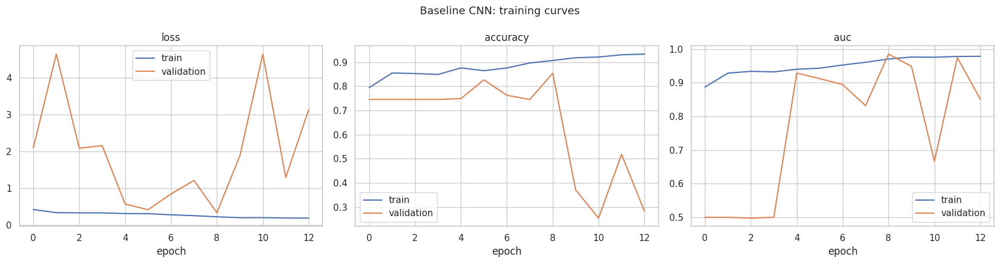

epoch/accuracy,▁▄▄▄▅▅▅▆▇▇▇██
epoch/auc,▁▄▅▄▅▅▆▇▇████
epoch/epoch,▁▂▂▃▃▄▅▅▆▆▇▇█
epoch/learning_rate,███████▃▃▃▁▁▁
epoch/loss,█▅▅▅▅▅▄▃▂▁▁▁▁
epoch/precision,▁▅▄▆▆▆▆▇▇█▇██
epoch/recall,▁▄▄▃▅▄▅▆▇▇▇██
epoch/val_accuracy,▇▇▇▇▇█▇▇█▂▁▄▁
epoch/val_auc,▁▁▁▁▇▇▇▆█▇▃█▆
epoch/val_loss,▄█▄▄▁▁▂▂▁▄█▃▆
+2,...


In [22]:
EPOCHS_BASELINE = 20
train_aug = augment_ds(train_ds)      # fresh random augmentation every epoch

wb_start("baseline-cnn", tags=["baseline"], config={
    "model": "baseline_cnn", "img_size": list(IMG_SIZE), "batch_size": BATCH_SIZE,
    "learning_rate": 1e-3, "max_epochs": EPOCHS_BASELINE, "class_weight": class_weight,
    "n_train_images": int(len(full[full["split"] == "train"])), "seed": SEED})

history_baseline = baseline_model.fit(
    train_aug,
    validation_data=val_ds,
    epochs=EPOCHS_BASELINE,
    class_weight=class_weight,
    callbacks=get_callbacks(patience=4) + tracking_callbacks("baseline_cnn"),
)
hist_baseline = merge_histories(history_baseline)
plot_history(hist_baseline, "Baseline CNN: training curves")
wandb.finish()

### After the cell: interpretation
Read the curves like this (confirm against your own plots and fill in the specifics):
- **Training and validation curves moving together** means the model is learning patterns that generalise. A large and growing gap (training loss falling while validation loss rises) means **overfitting**.
- **Noisy validation curves** are common with small validation sets and imbalanced data. Early stopping restores the best epoch, so the weights we keep are not necessarily the last epoch.
- Note the epoch where training stopped and the best validation AUC reached. This is the baseline that the transfer-learning model has to beat.
- If the validation metrics barely move from epoch to epoch, the baseline may be underfitting; a longer run or a lower starting learning rate can be tried.

## 9. Model 2: MobileNetV2 Transfer Learning

### 9.1 Why transfer learning here
MobileNetV2 was pretrained on ImageNet (millions of everyday photos). Even though X-rays look nothing like cats and cars, the early layers have already learned general visual building blocks (edges, textures, shapes), so we reuse them and only train a small classifier on top. This usually works much better than training from scratch on a few thousand images, and MobileNetV2 is **lightweight**, which matters for fast API responses and the load testing later.

We train in **two stages**:
1. **Feature extraction:** freeze the pretrained base and train only the new classification head.
2. **Fine-tuning:** unfreeze the last part of the base and train it with a very small learning rate so it adapts to X-rays without destroying what it already knows.

### 9.2 Build the model

#### Before the cell
- Input scaling: MobileNetV2 expects pixels in **[-1, 1]**, so `Rescaling(1/127.5, offset=-1)` is used instead of 1/255. It is a normal layer, so it is saved inside the model file.
- `base(x, training=False)` keeps the base's BatchNormalization layers in inference mode, which is important when the base is frozen or only partly unfrozen.
- Head: global average pooling, dropout, and one sigmoid unit (probability of PNEUMONIA), the same output as the baseline so the two are directly comparable.

In [23]:
def build_mobilenet():
    base = tf.keras.applications.MobileNetV2(
        input_shape=INPUT_SHAPE, include_top=False, weights="imagenet")
    base.trainable = False
    inputs = tf.keras.Input(shape=INPUT_SHAPE)
    x = L.Rescaling(1.0 / 127.5, offset=-1)(inputs)
    x = base(x, training=False)
    x = L.GlobalAveragePooling2D()(x)
    x = L.Dropout(0.3)(x)
    outputs = L.Dense(1, activation="sigmoid")(x)
    return tf.keras.Model(inputs, outputs, name="mobilenetv2_transfer"), base

def set_finetune_policy(model, n_last=30):
    # Unfreeze the last n_last layers of the pretrained base; keep BatchNorm layers frozen.
    bases = [l for l in model.layers if isinstance(l, tf.keras.Model)]
    if not bases:
        return model
    base = bases[0]
    base.trainable = True
    for layer in base.layers[:-n_last]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, L.BatchNormalization):
            layer.trainable = False
    return model

tf.keras.utils.set_random_seed(SEED)
mobilenet_model, mobilenet_base = build_mobilenet()
mobilenet_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                        loss="binary_crossentropy", metrics=get_metrics())
trainable = sum(int(np.prod(w.shape)) for w in mobilenet_model.trainable_weights)
total = mobilenet_model.count_params()
print(f"Trainable parameters (stage 1): {trainable:,} of {total:,}")

Trainable parameters (stage 1): 1,281 of 2,259,265


### After the cell
Only a tiny fraction of the parameters (the new head, about 1,300) is trainable in stage 1, while the pretrained base (about 2.2 million parameters) is frozen. This is why stage 1 is fast and hard to overfit.

### 9.3 Stage 1: train the classification head

#### Before the cell
The base is frozen and only the new head is trained, with a normal learning rate (1e-3).

In [24]:
wb_start("mobilenetv2", tags=["transfer-learning"], config={
    "model": "mobilenetv2_transfer", "pretrained_weights": "imagenet",
    "img_size": list(IMG_SIZE), "batch_size": BATCH_SIZE, "head_learning_rate": 1e-3,
    "class_weight": class_weight, "n_train_images": int(len(full[full["split"] == "train"])),
    "seed": SEED})

history_head = mobilenet_model.fit(
    train_aug,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weight,
    callbacks=get_callbacks(patience=3) + tracking_callbacks("mobilenetv2"),
)

Epoch 1/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 110s 697ms/step - accuracy: 0.7705 - auc: 0.8582 - loss: 0.4671 - precision: 0.9149 - recall: 0.7633 - val_accuracy: 0.9140 - val_auc: 0.9714 - val_loss: 0.2323 - val_precision: 0.9112 - val_recall: 0.9802 - learning_rate: 0.0010
Epoch 2/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 50s 411ms/step - accuracy: 0.8825 - auc: 0.9571 - loss: 0.2786 - precision: 0.9642 - recall: 0.8750 - val_accuracy: 0.9361 - val_auc: 0.9762 - val_loss: 0.1817 - val_precision: 0.9512 - val_recall: 0.9638 - learning_rate: 0.0010
Epoch 3/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 80s 400ms/step - accuracy: 0.9041 - auc: 0.9694 - loss: 0.2307 - precision: 0.9710 - recall: 0.8983 - val_accuracy: 0.9398 - val_auc: 0.9774 - val_loss: 0.1691 - val_precision: 0.9544 - val_recall: 0.9654 - learning_rate: 0.0010
Epoch 4/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 82s 393ms/step - accuracy: 0.9033 - auc: 0.9708 - loss: 0.2229 - precision: 0.9692 - recall: 0.8990 - val_accuracy: 0.9398 - val_auc: 0.9783 - val_loss:

### After the cell: interpretation
- With a frozen pretrained base, validation AUC usually rises quickly in the first few epochs. Note where it levels off.
- If stage-1 results are already strong, fine-tuning is the polish that may add a further small gain; if they are weak, fine-tuning is where most of the improvement can come from, since X-rays differ from ImageNet photos.

### 9.4 Stage 2: fine-tune the top of the base

#### Before the cell
We unfreeze the last 30 layers of MobileNetV2 (keeping BatchNorm layers frozen for stability) and **recompile with a 100x smaller learning rate (1e-5)**. Recompiling is required for the new `trainable` flags to take effect. A small learning rate is critical: large updates would wipe out the pretrained features.

Trainable parameters (stage 2): 1,512,001
Epoch 11/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 80s 531ms/step - accuracy: 0.9239 - auc: 0.9794 - loss: 0.1818 - precision: 0.9735 - recall: 0.9230 - val_accuracy: 0.9545 - val_auc: 0.9815 - val_loss: 0.1321 - val_precision: 0.9657 - val_recall: 0.9736 - learning_rate: 1.0000e-05
Epoch 12/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 49s 407ms/step - accuracy: 0.9326 - auc: 0.9852 - loss: 0.1538 - precision: 0.9784 - recall: 0.9301 - val_accuracy: 0.9484 - val_auc: 0.9865 - val_loss: 0.1400 - val_precision: 0.9796 - val_recall: 0.9506 - learning_rate: 1.0000e-05
Epoch 13/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 392ms/step - accuracy: 0.9444 - auc: 0.9853 - loss: 0.1522 - precision: 0.9819 - recall: 0.9439
Epoch 13: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
119/119 ━━━━━━━━━━━━━━━━━━━━ 48s 399ms/step - accuracy: 0.9452 - auc: 0.9880 - loss: 0.1391 - precision: 0.9813 - recall: 0.9445 - val_accuracy: 0.9472 - val_auc: 0.9869 - val_loss: 0.1370 - v

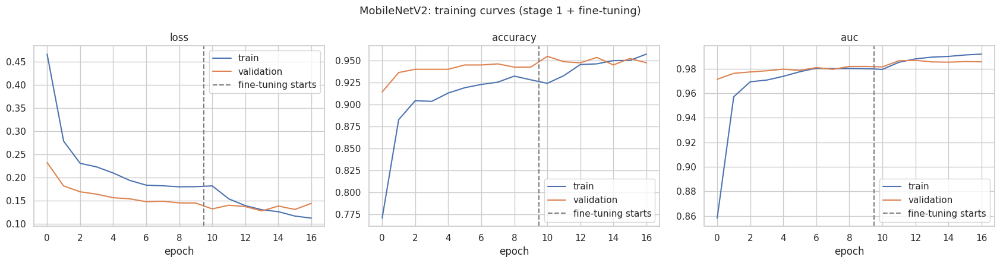

epoch/accuracy,▁▅▆▆▆▇▇▇▇▇▇▇█████
epoch/auc,▁▆▇▇▇▇▇▇▇▇▇██████
epoch/epoch,▁▁▂▂▃▃▄▄▅▅▅▆▆▇▇██
epoch/learning_rate,██████████▁▁▁▁▁▁▁
epoch/loss,█▄▃▃▃▃▂▂▂▂▂▂▂▁▁▁▁
epoch/precision,▁▆▆▆▆▇▇▇▇▇▇▇▇████
epoch/recall,▁▅▆▆▆▇▇▇▇▇▇▇█████
epoch/val_accuracy,▁▅▅▅▅▆▆▇▆▆█▇▇█▆█▇
epoch/val_auc,▁▃▄▄▅▄▅▅▆▆▆██▇▇█▇
epoch/val_loss,█▅▄▃▃▃▂▂▂▂▁▂▂▁▂▁▂
+2,...


In [25]:
set_finetune_policy(mobilenet_model, n_last=30)
mobilenet_model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                        loss="binary_crossentropy", metrics=get_metrics())
trainable = sum(int(np.prod(w.shape)) for w in mobilenet_model.trainable_weights)
print(f"Trainable parameters (stage 2): {trainable:,}")

wandb.config.update({"finetune_learning_rate": 1e-5, "finetune_unfrozen_layers": 30})

n_head = len(history_head.history["loss"])          # epochs already done in stage 1
history_ft = mobilenet_model.fit(
    train_aug,
    validation_data=val_ds,
    epochs=n_head + 10,
    initial_epoch=n_head,                             # keeps epoch numbering continuous in the logs
    class_weight=class_weight,
    callbacks=get_callbacks(patience=3) + tracking_callbacks("mobilenetv2"),
)

hist_mobilenet = merge_histories(history_head, history_ft)
plot_history(hist_mobilenet, "MobileNetV2: training curves (stage 1 + fine-tuning)",
             finetune_start=n_head)
wandb.finish()

### After the cell: interpretation
- The dashed line marks where fine-tuning starts. Check whether validation loss and AUC **improve, stay flat, or get worse** after it.
- Improvement after the line means adapting the pretrained features to X-rays helped. If validation metrics get worse while training metrics keep improving, the model began to overfit and the early-stopping checkpoint (best epoch) is what we keep.
- Compare the gap between training and validation curves with the baseline's. A smaller gap suggests better generalisation.

### 9.5 View the runs in TensorBoard

#### Before the cell
This opens TensorBoard inside the notebook. Use the **Scalars** tab to compare the baseline and MobileNetV2 runs (loss, accuracy, precision, recall, AUC per epoch). The same runs are also in your W&B project.

In [26]:
%load_ext tensorboard
%tensorboard --logdir /content/pneumonia_project/logs

<IPython.core.display.Javascript object>

### After the cell
Select both runs (`baseline_cnn`, `mobilenetv2`) on the left and compare the validation curves. Take a screenshot for the report. If the viewer shows nothing, wait a few seconds and press the refresh icon.

## 10. Model Evaluation

We evaluate both models properly on **validation** (used to choose between models and to set the decision threshold) and **test** (touched only for final reporting). Choosing the model or threshold using the test set would leak information and make the final numbers optimistic.

### 10.1 Predicted probabilities

#### Before the cell
We collect the true labels and each model's predicted probability of PNEUMONIA for the validation and test sets. `val_ds` and `test_ds` are not shuffled, so labels and predictions line up image by image. Every metric below is computed from these arrays.

In [27]:
def get_labels(ds):
    return np.concatenate([y.numpy().ravel() for _, y in ds]).astype(int)

def predict_probs(model, ds):
    return model.predict(ds, verbose=0).ravel()

y_val = get_labels(val_ds)
y_test = get_labels(test_ds)

models = {"Baseline CNN": baseline_model, "MobileNetV2": mobilenet_model}
P = {name: {"val": predict_probs(m, val_ds), "test": predict_probs(m, test_ds)}
     for name, m in models.items()}

print("Validation images:", len(y_val), "| Test images:", len(y_test))
print("Test class counts (NORMAL, PNEUMONIA):", np.bincount(y_test))

Validation images: 814 | Test images: 814
Test class counts (NORMAL, PNEUMONIA): [207 607]


### After the cell
The counts should match Section 4.1 (814 validation and 814 test images, with about 25% NORMAL and 75% PNEUMONIA). If they do not, a dataset was shuffled or rebuilt between cells.

### 10.2 Metrics at the default threshold (0.5)

#### Before the cell
Metrics reported for each model, with what they mean here (PNEUMONIA is the positive class):

- **Accuracy:** share of all predictions that are right. Misleading with 75% PNEUMONIA.
- **Precision:** of images flagged as pneumonia, how many really are.
- **Recall (sensitivity):** of real pneumonia cases, how many were caught. **Missing a case is the costly error in screening.**
- **Specificity:** of healthy images, how many were correctly called normal.
- **F1:** balance of precision and recall.
- **ROC-AUC:** how well the model ranks pneumonia above normal across all thresholds (1.0 is perfect, 0.5 is random).

In [28]:
def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) else 0.0,
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

rows = []
for name in P:
    for split, y in (("val", y_val), ("test", y_test)):
        rows.append({"model": name, "split": split, **compute_metrics(y, P[name][split])})
results = pd.DataFrame(rows).set_index(["model", "split"])
display(results.round(4))

accuracy  precision  recall  specificity      f1  roc_auc  \
model        split                                                              
Baseline CNN val      0.8538     0.9939  0.8089       0.9855  0.8919   0.9850   
             test     0.8600     0.9901  0.8204       0.9758  0.8973   0.9772   
MobileNetV2  val      0.9533     0.9782  0.9588       0.9372  0.9684   0.9874   
             test     0.9570     0.9719  0.9703       0.9179  0.9711   0.9848   

                     TN  FP   FN   TP  
model        split                     
Baseline CNN val    204   3  116  491  
             test   202   5  109  498  
MobileNetV2  val    194  13   25  582  
             test   190  17   18  589

### After the cell: interpretation
Fill in after looking at your table:
- **Which model has the higher ROC-AUC and F1?** Transfer learning is expected to do better, but verify it.
- **Recall vs specificity:** a model with very high recall but low specificity is calling too many healthy patients pneumonia (many false positives). The reverse means it is missing real cases. Compare the two.
- **Validation vs test:** the numbers should be close. A big drop on test would mean the model (or the model choice) overfit the validation set.
- Remember the size bias found in Section 5.3: a very high score may partly reflect image size or acquisition differences, not only lung disease.

### 10.3 Confusion matrices (test set)

#### Before the cell
A confusion matrix shows exactly *which* mistakes are made. The row is the true class and the column is the predicted class. **False negatives** (pneumonia predicted as normal) are the most dangerous errors here. **False positives** (normal predicted as pneumonia) lead to unnecessary follow-up.

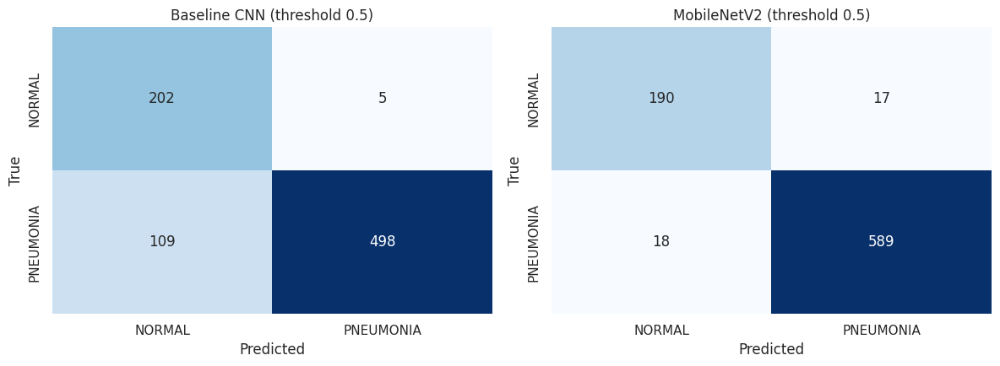

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, P):
    y_pred = (P[name]["test"] >= 0.5).astype(int)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASSES, yticklabels=CLASSES)
    ax.set_title(f"{name} (threshold 0.5)")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.show()

### After the cell: interpretation
- Read the **bottom-left cell** (true PNEUMONIA predicted NORMAL) first: it is the number of missed cases.
- Then the **top-right cell** (true NORMAL predicted PNEUMONIA): these are false alarms.
- Compare how the two models distribute their errors. One may trade more false alarms for fewer misses, which is often the preferred direction in screening. Write down the actual counts here.

### 10.4 ROC curves (test set)

#### Before the cell
The ROC curve plots the true-positive rate against the false-positive rate for every possible threshold. The closer a curve hugs the top-left corner, the better; the dashed diagonal is random guessing. The area under it (AUC) summarises the curve in a single number.

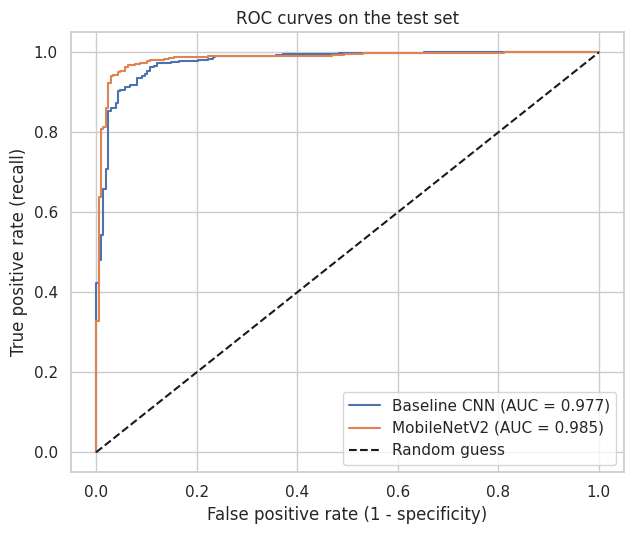

In [30]:
plt.figure(figsize=(6.5, 5.5))
for name in P:
    fpr, tpr, _ = roc_curve(y_test, P[name]["test"])
    auc = roc_auc_score(y_test, P[name]["test"])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate (1 - specificity)")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curves on the test set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### After the cell: interpretation
- The model whose curve sits higher (and has the larger AUC) separates the two classes better **regardless of the threshold chosen**.
- Look at the left part of the curve: how much recall is reached while keeping false positives very low? That tells you how well the model can work at a strict operating point.
- Both curves should be clearly above the diagonal. If one is near it, that model has learned very little.

### 10.5 Select the best model

#### Before the cell
The model is chosen using **validation F1** (not test), because it balances catching pneumonia and avoiding false alarms, and because the test set must remain untouched for the final report.

In [31]:
val_table = results.xs("val", level="split")
best_name = val_table["f1"].idxmax()
best_model = models[best_name]
print("Validation F1 per model:")
print(val_table["f1"].round(4).to_string())
print("\nSelected model:", best_name)

Validation F1 per model:
model
Baseline CNN    0.8919
MobileNetV2     0.9684

Selected model: MobileNetV2


### After the cell
This is the model that will be saved, deployed, and retrained. State here which model won and by how much, using the validation F1 values above.

### 10.6 Detailed classification report (selected model, test set)

#### Before the cell
`classification_report` gives precision, recall and F1 **per class**, plus macro and weighted averages. The macro average treats both classes equally and is therefore more honest than overall accuracy on imbalanced data.

In [32]:
y_pred_best = (P[best_name]["test"] >= 0.5).astype(int)
print(f"Classification report: {best_name} on the test set (threshold 0.5)\n")
print(classification_report(y_test, y_pred_best, target_names=CLASSES, digits=4))

Classification report: MobileNetV2 on the test set (threshold 0.5)

              precision    recall  f1-score   support

      NORMAL     0.9135    0.9179    0.9157       207
   PNEUMONIA     0.9719    0.9703    0.9711       607

    accuracy                         0.9570       814
   macro avg     0.9427    0.9441    0.9434       814
weighted avg     0.9571    0.9570    0.9570       814



### After the cell: interpretation
- Compare the **recall of PNEUMONIA** with the **recall of NORMAL**. The NORMAL row is the same as specificity; it is usually lower for the majority-heavy dataset because there are fewer normal examples to learn from.
- The **macro average F1** shows how balanced the model is across both classes. If it sits well below the weighted average, the minority class is still being handled worse.

### 10.7 Choosing the decision threshold

#### Before the cell
By default an image is called PNEUMONIA when the predicted probability is at least 0.5, but 0.5 is arbitrary. For screening, missing a case is worse than a false alarm, so we choose the threshold **on the validation set** as the one that keeps recall at or above **95%** while giving the best precision possible at that recall. We then apply it to the untouched test set to see the real effect. This threshold is stored with the model and used by the API.

Chosen threshold (from validation data): 0.620


,accuracy,precision,recall,specificity,f1,roc_auc,TN,FP,FN,TP
threshold 0.5,0.957,0.9719,0.9703,0.9179,0.9711,0.9848,190.0,17.0,18.0,589.0
threshold 0.620,0.957,0.9799,0.9621,0.9420,0.9709,0.9848,195.0,12.0,23.0,584.0


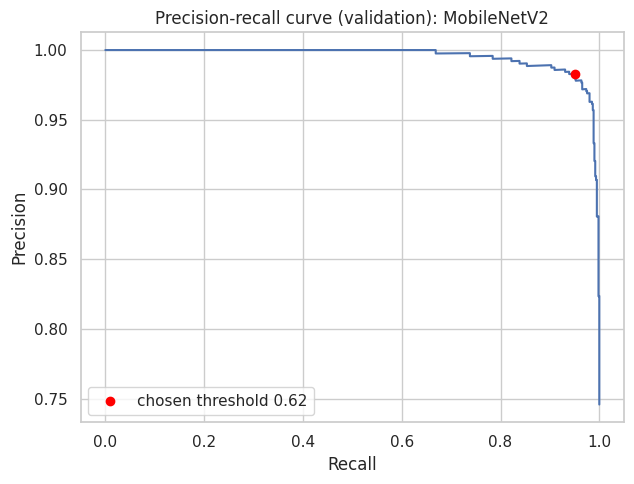

In [33]:
def pick_threshold(y_true, y_prob, min_recall=0.95):
    prec, rec, thr = precision_recall_curve(y_true, y_prob)
    ok = np.where(rec[:-1] >= min_recall)[0]
    if len(ok) == 0:
        return 0.5
    best = ok[np.argmax(prec[:-1][ok])]
    return float(thr[best])

THRESHOLD = pick_threshold(y_val, P[best_name]["val"], min_recall=0.95)
print(f"Chosen threshold (from validation data): {THRESHOLD:.3f}")

compare = pd.DataFrame({
    "threshold 0.5": compute_metrics(y_test, P[best_name]["test"], 0.5),
    f"threshold {THRESHOLD:.3f}": compute_metrics(y_test, P[best_name]["test"], THRESHOLD),
}).T
display(compare.round(4))

prec, rec, thr = precision_recall_curve(y_val, P[best_name]["val"])
plt.figure(figsize=(6.5, 5))
plt.plot(rec, prec)
idx = np.argmin(np.abs(thr - THRESHOLD))
plt.scatter(rec[idx], prec[idx], color="red", zorder=3, label=f"chosen threshold {THRESHOLD:.2f}")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title(f"Precision-recall curve (validation): {best_name}")
plt.legend(); plt.tight_layout(); plt.show()

### After the cell: interpretation
- Compare the two rows. Lowering the threshold normally **raises recall (fewer missed cases) and lowers precision/specificity (more false alarms)**. Quantify the trade-off using your numbers: how many fewer false negatives, and how many more false positives?
- If the test recall is close to the 95% target, the validation-based choice generalised. If it is clearly different, the validation set is small or unrepresentative, and the threshold should be treated as approximate.
- This operating point is a **design decision for a screening use case**, not a clinical standard, and it should be explained as such in the report.

### 10.8 Error analysis: which images does the model get wrong?

#### Before the cell
Numbers do not show *why* a model fails, so we look at the actual mistakes: the **most confident false negatives** (pneumonia predicted normal) and **most confident false positives** (normal predicted pneumonia). We rebuild an unshuffled test dataset only to get the file paths in the same order as the predictions.

Found 814 files belonging to 2 classes.
False negatives: 23 | False positives: 12


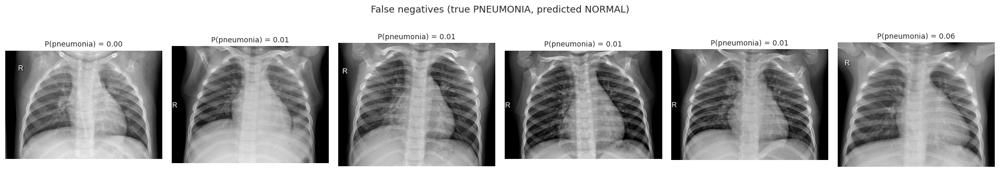

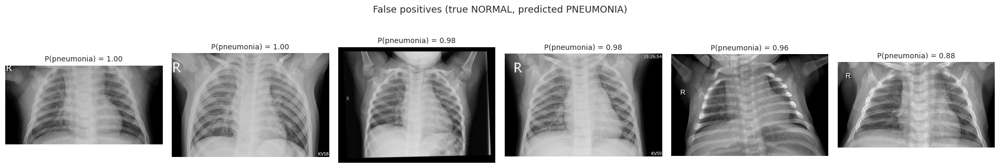

In [34]:
test_raw = tf.keras.utils.image_dataset_from_directory(DATA_DIR / "test", shuffle=False, **common)
test_paths = np.array(test_raw.file_paths)
assert (get_labels(test_raw) == y_test).all(), "Label order mismatch"

prob = P[best_name]["test"]
pred = (prob >= THRESHOLD).astype(int)
fn_idx = np.where((y_test == 1) & (pred == 0))[0]
fp_idx = np.where((y_test == 0) & (pred == 1))[0]
fn_idx = fn_idx[np.argsort(prob[fn_idx])]            # most confidently wrong first
fp_idx = fp_idx[np.argsort(-prob[fp_idx])]
print(f"False negatives: {len(fn_idx)} | False positives: {len(fp_idx)}")

def show_cases(idx, title, n=6):
    idx = idx[:n]
    if len(idx) == 0:
        print(f"No {title.lower()}.")
        return
    fig, axes = plt.subplots(1, len(idx), figsize=(3.2 * len(idx), 3.6))
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, idx):
        ax.imshow(Image.open(test_paths[i]).convert("L"), cmap="gray")
        ax.set_title(f"P(pneumonia) = {prob[i]:.2f}", fontsize=10)
        ax.axis("off")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

show_cases(fn_idx, "False negatives (true PNEUMONIA, predicted NORMAL)")
show_cases(fp_idx, "False positives (true NORMAL, predicted PNEUMONIA)")

### After the cell: interpretation
Look at the images and write your own observations. Things worth checking:
- Do the **false negatives** show faint or small opacities, or poor image quality, that would be hard even for a person?
- Do the **false positives** show anything unusual (rotation, markers, low contrast, an unusually bright image) that could have confused the model?
- Are the errors concentrated in a certain type of image (very large or very small, very dark or bright)? If so, that links back to the size and brightness findings in Section 5.
- Conclude with how these error patterns affect the intended use: this model is a **screening aid**, and every flagged or missed case would need a clinician's review.

### 10.9 Log the evaluation to Weights & Biases

#### Before the cell
We record the final evaluation in W&B so it sits next to the training runs: the full metrics table, the selected model and threshold, and the test confusion matrix and ROC curve for the selected model.

In [35]:
prob_best = P[best_name]["test"]
pred_best = (prob_best >= THRESHOLD).astype(int)
final = compute_metrics(y_test, prob_best, THRESHOLD)

wb_start("evaluation", tags=["evaluation"], config={"selected_model": best_name, "threshold": THRESHOLD})
wandb.log({
    "results_table": wandb.Table(dataframe=results.reset_index().round(4)),
    "test/confusion_matrix": wandb.plot.confusion_matrix(
        y_true=y_test, preds=pred_best, class_names=CLASSES),
    "test/roc_curve": wandb.plot.roc_curve(
        y_test, np.stack([1 - prob_best, prob_best], axis=1), labels=CLASSES),
})
for k in ("accuracy", "precision", "recall", "specificity", "f1", "roc_auc"):
    wandb.run.summary[f"test_{k}"] = float(final[k])
wandb.finish()
print("Evaluation logged. Test recall at threshold:", round(final["recall"], 4))

wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


test_accuracy,0.957
test_f1,0.97091
test_precision,0.97987
test_recall,0.96211
test_roc_auc,0.98475
test_specificity,0.94203


Evaluation logged. Test recall at threshold: 0.9621


### After the cell
Open your W&B project: the `evaluation` run holds the comparison table, the confusion matrix and the ROC curve, and its summary shows the headline test metrics (the numbers to quote in the report).

## 11. Save the Model and its Metadata

### 11.1 Save

#### Before the cell
We save the selected model as **`.h5`** (the format the assignment lists) and as **`.keras`** (the current native Keras format, as a safe alternative). Input scaling is inside the model (augmentation is not, see Section 8.1), so the saved file is a self-contained inference model.

A small **metadata JSON** is saved beside it with everything the API needs and nothing it should guess: class order, image size, the decision threshold, the model name and version, and the test metrics. A versioned copy (`pneumonia_model_v1.h5`) is also kept, so a retrained model can be compared with, or rolled back to, the original.

In [36]:
MODEL_PATH = MODELS_DIR / "pneumonia_model.h5"
META_PATH = MODELS_DIR / "model_metadata.json"

best_model.save(MODEL_PATH)
best_model.save(MODELS_DIR / "pneumonia_model.keras")
shutil.copy2(MODEL_PATH, MODELS_DIR / "pneumonia_model_v1.h5")

def save_metadata(meta):
    META_PATH.write_text(json.dumps(meta, indent=2))

def load_metadata():
    return json.loads(META_PATH.read_text())

test_at_thr = compute_metrics(y_test, P[best_name]["test"], THRESHOLD)
metadata = {
    "model_name": best_name,
    "version": 1,
    "classes": CLASSES,
    "img_size": list(IMG_SIZE),
    "threshold": THRESHOLD,
    "trained_at": datetime.datetime.now().isoformat(timespec="seconds"),
    "n_train_images": int(len(full[full["split"] == "train"])),
    "test_metrics": {k: (round(float(v), 4) if isinstance(v, float) else int(v))
                     for k, v in test_at_thr.items()},
}
save_metadata(metadata)

for p in sorted(MODELS_DIR.iterdir()):
    print(f"{p.name:30s} {p.stat().st_size / 1e6:7.2f} MB")
print(json.dumps(metadata, indent=2))

# Register this version as a W&B artifact (versioned model storage)
wb_start("register-model-v1", tags=["model-registry"], config=metadata)
art = wandb.Artifact("pneumonia-model", type="model", metadata=metadata)
art.add_file(str(MODEL_PATH))
art.add_file(str(META_PATH))
wandb.log_artifact(art, aliases=["v1", "deployed"])
wandb.finish()

model_metadata.json               0.00 MB
pneumonia_model.h5               21.51 MB
pneumonia_model.keras            21.73 MB
pneumonia_model_v1.h5            21.51 MB
{
  "model_name": "MobileNetV2",
  "version": 1,
  "classes": [
    "NORMAL",
    "PNEUMONIA"
  ],
  "img_size": [
    224,
    224
  ],
  "threshold": 0.6201691031455994,
  "trained_at": "2026-11-19T20:58:21",
  "n_train_images": 3796,
  "test_metrics": {
    "accuracy": 0.957,
    "precision": 0.9799,
    "recall": 0.9621,
    "specificity": 0.942,
    "f1": 0.9709,
    "roc_auc": 0.9848,
    "TN": 195,
    "FP": 12,
    "FN": 23,
    "TP": 584
  }
}


### After the cell
- You should see `pneumonia_model.h5`, `pneumonia_model.keras`, `pneumonia_model_v1.h5` and `model_metadata.json`.
- A Keras warning that `.h5` is a legacy format is expected and harmless. The `.h5` file is the one named in the assignment, and `.keras` is the backup.
- File size should be small (a few MB for MobileNetV2), which is good for fast Docker builds and container start-up.

### 11.2 Reload test

#### Before the cell
A saved model is only useful if it loads and behaves identically. We reload the `.h5` file in a clean way (as the API will) and confirm that its predictions match the original model's. The difference should be essentially zero.

In [37]:
deployed_model = tf.keras.models.load_model(MODEL_PATH)
reloaded_probs = predict_probs(deployed_model, test_ds)
max_diff = np.abs(reloaded_probs - P[best_name]["test"]).max()
print(f"Largest probability difference after reload: {max_diff:.2e}")
assert max_diff < 1e-3, "Reloaded model does not match the original"
print("Reload check passed.")

Largest probability difference after reload: 0.00e+00
Reload check passed.


### After the cell
A difference around 1e-6 or smaller (pure floating-point noise) and the message `Reload check passed.` confirm the saved file is faithful. If the assertion fails, use the `.keras` file instead and tell me, so we can fix the format before building the API.

## 12. Prediction Function (single image)

### 12.1 Define the function

#### Before the cell
This is the function the API will call for the **"predict one datapoint"** feature. It takes a file path or raw image bytes (an uploaded file arrives as bytes) and returns the label, the probability and a confidence value.

The image must be preprocessed **exactly as in training**: decoded to 3-channel RGB, resized to 224 x 224 with **bilinear interpolation** using TensorFlow (the same method as `image_dataset_from_directory`), left in 0 to 255 (scaling happens inside the model). Using a different resizer, for example PIL's, would shift pixel values slightly and could lower accuracy in production without any error message, which is why the next cell verifies the match.

In [38]:
PRED_THRESHOLD = load_metadata()["threshold"]

def preprocess_image(image):
    # image: file path (str / Path) or raw bytes
    if isinstance(image, (str, Path)):
        image = Path(image).read_bytes()
    img = tf.io.decode_image(image, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE, method="bilinear")
    return tf.cast(img, tf.float32)

def predict_image(image, model=None, threshold=None):
    model = model or deployed_model
    threshold = PRED_THRESHOLD if threshold is None else threshold
    x = tf.expand_dims(preprocess_image(image), 0)
    p_pneumonia = float(model(x, training=False).numpy()[0][0])
    label = "PNEUMONIA" if p_pneumonia >= threshold else "NORMAL"
    confidence = p_pneumonia if label == "PNEUMONIA" else 1 - p_pneumonia
    return {
        "label": label,
        "probability_pneumonia": round(p_pneumonia, 4),
        "confidence": round(confidence, 4),
        "threshold": round(threshold, 4),
    }

print(predict_image(test_paths[0]))

{'label': 'NORMAL', 'probability_pneumonia': 0.0085, 'confidence': 0.9915, 'threshold': 0.6202}


### After the cell
The output is a dictionary such as `{'label': ..., 'probability_pneumonia': ..., 'confidence': ..., 'threshold': ...}`. This dictionary becomes the JSON the API returns.

### 12.2 Verify it matches the evaluation pipeline

#### Before the cell
We run `predict_image` on 25 random test images and compare its probabilities with the ones from the batch evaluation in Section 10. If preprocessing differs anywhere, the values will not agree. This guards against the most common deployment bug: a model that scores well in the notebook but worse behind the API.

In [39]:
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(test_paths), size=25, replace=False)
single = np.array([predict_image(test_paths[i])["probability_pneumonia"] for i in sample_idx])
batch = P[best_name]["test"][sample_idx]
print("Largest difference (single-image vs batch):", np.abs(single - batch).max())
assert np.abs(single - batch).max() < 5e-3
print("Prediction function matches the evaluation pipeline.")

Largest difference (single-image vs batch): 4.707107543944211e-05
Prediction function matches the evaluation pipeline.


### After the cell
A difference of the order of 1e-4 or less (we round to 4 decimals) means the function is consistent with the evaluation pipeline. Keep these preprocessing steps identical in `src/preprocessing.py` and the API.

### 12.3 Example predictions

#### Before the cell
A visual demonstration for the report and demo video: one NORMAL and one PNEUMONIA image from the test set, with the model's output.

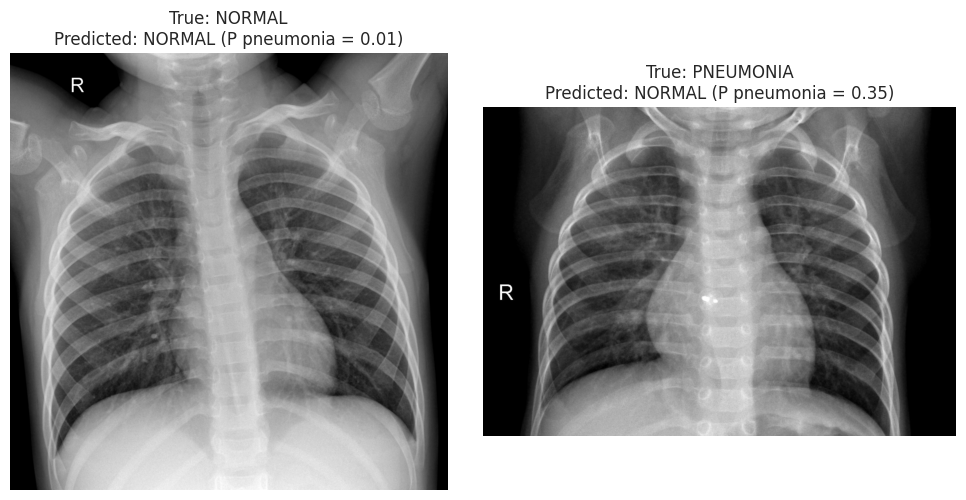

In [40]:
examples = [int(np.where(y_test == 0)[0][0]), int(np.where(y_test == 1)[0][0])]
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, i in zip(axes, examples):
    out = predict_image(test_paths[i])
    ax.imshow(Image.open(test_paths[i]).convert("L"), cmap="gray")
    ax.set_title(f"True: {CLASSES[y_test[i]]}\nPredicted: {out['label']} "
                 f"(P pneumonia = {out['probability_pneumonia']:.2f})")
    ax.axis("off")
plt.tight_layout()
plt.show()

### After the cell
State whether both examples were classified correctly. A single example does not prove the model is good; the metrics in Section 10 do. This is a demonstration of how the prediction flow works.

## 13. Model Retraining

The assignment requires that the model can be **retrained on newly uploaded data, with a trigger**. We implement three pieces: a **trigger** that decides when retraining is needed, a **retraining function** that continues training the existing model on old plus new data, and a **promotion rule** so a worse model never replaces a better one.

### 13.1 The retraining trigger

#### Before the cell
Retraining is triggered by either of two conditions:
1. **Enough new data:** at least `RETRAIN_MIN_NEW_IMAGES` (50) newly uploaded images are waiting.
2. **Performance drop:** accuracy measured on recent labelled data falls more than 5 percentage points below the accuracy at deployment time.

The API will call this function after every upload, and the UI also offers a manual **Retrain** button that skips the check.

In [41]:
RETRAIN_MIN_NEW_IMAGES = 50
RETRAIN_MAX_ACCURACY_DROP = 0.05

def count_images(folder):
    return sum(1 for p in Path(folder).rglob("*") if p.suffix.lower() in VALID_EXT)

def should_retrain(new_data_dir, live_accuracy=None, baseline_accuracy=None):
    reasons = []
    n_new = count_images(new_data_dir)
    if n_new >= RETRAIN_MIN_NEW_IMAGES:
        reasons.append(f"{n_new} new images uploaded (threshold {RETRAIN_MIN_NEW_IMAGES})")
    if live_accuracy is not None and baseline_accuracy is not None:
        if baseline_accuracy - live_accuracy > RETRAIN_MAX_ACCURACY_DROP:
            reasons.append(f"accuracy fell from {baseline_accuracy:.3f} to {live_accuracy:.3f}")
    return {"retrain": bool(reasons), "n_new_images": n_new, "reasons": reasons}

empty_dir = WORK_DIR / "empty_check"
empty_dir.mkdir(exist_ok=True)
print("No new data:         ", should_retrain(empty_dir))
print("400 new images:      ", should_retrain(DATA_DIR / "new_data"))
print("Accuracy drop only:  ", should_retrain(empty_dir, live_accuracy=0.84, baseline_accuracy=0.93))

No new data:          {'retrain': False, 'n_new_images': 0, 'reasons': []}
400 new images:       {'retrain': True, 'n_new_images': 400, 'reasons': ['400 new images uploaded (threshold 50)']}
Accuracy drop only:   {'retrain': True, 'n_new_images': 0, 'reasons': ['accuracy fell from 0.930 to 0.840']}


### After the cell
The first call should say `retrain: False`, and the other two `retrain: True` with the reason listed. These thresholds are deliberately simple and explainable. In a real service they would be tuned, and the accuracy check would use labelled feedback from clinicians.

### 13.2 The retraining function

#### Before the cell
`retrain_model` does the following:

1. Loads the **currently deployed** model, so we continue from what it already learned instead of starting over.
2. Combines the original training data with the new data and **recomputes class weights** from the combined counts.
3. Fine-tunes with a **very small learning rate (1e-5)** and a few epochs, so the model adapts without forgetting.
4. Compares old and new on the **same validation set**, and **promotes the new model only if it is not worse**: validation F1 may not drop by more than 1 point and recall may not drop by more than 2 points. Otherwise the old model stays live.
5. Saves a versioned file, updates the metadata, and appends to a retraining log.

The API's retrain endpoint will call this same function.

In [42]:
def retrain_model(train_dir, new_data_dir, val_ds, y_val, epochs=5, lr=1e-5,
                  max_f1_drop=0.01, max_recall_drop=0.02):
    meta = load_metadata()
    thr = meta["threshold"]
    old_version = meta["version"]
    model = tf.keras.models.load_model(MODEL_PATH)

    old_val = compute_metrics(y_val, predict_probs(model, val_ds), thr)

    old_ds = tf.keras.utils.image_dataset_from_directory(train_dir, shuffle=True, **common).unbatch()
    new_ds = tf.keras.utils.image_dataset_from_directory(new_data_dir, shuffle=True, **common).unbatch()
    combined = augment_ds(old_ds.concatenate(new_ds).shuffle(2000, seed=SEED)
                          .batch(BATCH_SIZE))

    counts = np.array([count_images(Path(train_dir) / c) + count_images(Path(new_data_dir) / c)
                       for c in CLASSES], dtype=float)
    cw = {i: float(counts.sum() / (2 * counts[i])) for i in range(2)}

    set_finetune_policy(model)
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss="binary_crossentropy", metrics=get_metrics())
    model.fit(combined, validation_data=val_ds, epochs=epochs, class_weight=cw,
              callbacks=get_callbacks(patience=2), verbose=2)

    new_val = compute_metrics(y_val, predict_probs(model, val_ds), thr)
    promoted = (new_val["f1"] >= old_val["f1"] - max_f1_drop and
                new_val["recall"] >= old_val["recall"] - max_recall_drop)

    new_version = old_version + 1
    candidate_path = MODELS_DIR / f"pneumonia_model_v{new_version}.h5"
    model.save(candidate_path)

    if promoted:
        shutil.copy2(candidate_path, MODEL_PATH)
        meta.update({"version": new_version,
                     "trained_at": datetime.datetime.now().isoformat(timespec="seconds"),
                     "n_train_images": int(counts.sum()),
                     "val_metrics_at_retrain": {k: round(float(v), 4) for k, v in new_val.items()
                                                if k in ("accuracy", "precision", "recall", "f1", "roc_auc")}})
        save_metadata(meta)

    result = {"old_version": old_version, "new_version": new_version, "promoted": bool(promoted),
              "n_train_old": int(sum(count_images(Path(train_dir) / c) for c in CLASSES)),
              "n_new": int(sum(count_images(Path(new_data_dir) / c) for c in CLASSES)),
              "old_val": old_val, "new_val": new_val, "class_weights": cw}

    log_path = MODELS_DIR / "retrain_log.json"
    log = json.loads(log_path.read_text()) if log_path.exists() else []
    log.append({"time": datetime.datetime.now().isoformat(timespec="seconds"),
                "old_version": old_version, "new_version": new_version,
                "promoted": bool(promoted), "n_new": result["n_new"],
                "val_f1_old": round(old_val["f1"], 4), "val_f1_new": round(new_val["f1"], 4)})
    log_path.write_text(json.dumps(log, indent=2))
    return result

print("retrain_model defined.")

retrain_model defined.


### After the cell
The function is only defined here. The next cell runs it. The promotion rule is a **safety net**: retraining on a small batch can occasionally make a model slightly worse, and an automatic system should not silently deploy that.

### 13.3 Run the retraining flow end to end

#### Before the cell
This simulates what a user does in the UI: new images are uploaded (here, the 400 held-out images in `data/new_data`, which the model has never seen), the trigger fires, and retraining runs. Validation and test sets are unchanged, so the comparison between old and new is fair.

In [46]:
decision = should_retrain(DATA_DIR / "new_data")
print("Trigger decision:", decision)

if decision["retrain"]:
    retrain_result = retrain_model(DATA_DIR / "train", DATA_DIR / "new_data", val_ds, y_val)
    print("\nPromoted new model:", retrain_result["promoted"],
          f"(v{retrain_result['old_version']} -> v{retrain_result['new_version']})")
    print("Training images used:", retrain_result["n_train_old"], "+", retrain_result["n_new"], "new")

    # Record the retraining run in W&B
    wb_start(f"retrain-v{retrain_result['new_version']}", tags=["retraining"], config={
        "trigger_reasons": decision["reasons"], "n_new_images": decision["n_new_images"],
        "promoted": retrain_result["promoted"], "class_weights": retrain_result["class_weights"]})
    wandb.log({f"val_old/{k}": float(v) for k, v in retrain_result["old_val"].items()
               if k in ("accuracy", "precision", "recall", "f1", "roc_auc")})
    wandb.log({f"val_new/{k}": float(v) for k, v in retrain_result["new_val"].items()
               if k in ("accuracy", "precision", "recall", "f1", "roc_auc")})
    cand = MODELS_DIR / f"pneumonia_model_v{retrain_result['new_version']}.h5"
    art = wandb.Artifact("pneumonia-model", type="model", metadata={
        "version": retrain_result["new_version"], "promoted": retrain_result["promoted"]})
    art.add_file(str(cand))
    wandb.log_artifact(art, aliases=[f"v{retrain_result['new_version']}"] +
                       (["deployed"] if retrain_result["promoted"] else []))
    wandb.finish()

Trigger decision: {'retrain': True, 'n_new_images': 400, 'reasons': ['400 new images uploaded (threshold 50)']}


Found 3796 files belonging to 2 classes.
Found 400 files belonging to 2 classes.
Epoch 1/5
132/132 - 109s - 825ms/step - accuracy: 0.9550 - auc: 0.9920 - loss: 0.1103 - precision: 0.9850 - recall: 0.9522 - val_accuracy: 0.9423 - val_auc: 0.9869 - val_loss: 0.1512 - val_precision: 0.9861 - val_recall: 0.9357 - learning_rate: 1.0000e-05
Epoch 2/5
132/132 - 123s - 928ms/step - accuracy: 0.9623 - auc: 0.9927 - loss: 0.1038 - precision: 0.9865 - recall: 0.9611 - val_accuracy: 0.9496 - val_auc: 0.9872 - val_loss: 0.1387 - val_precision: 0.9846 - val_recall: 0.9473 - learning_rate: 1.0000e-05
Epoch 3/5
132/132 - 94s - 712ms/step - accuracy: 0.9554 - auc: 0.9927 - loss: 0.1064 - precision: 0.9853 - recall: 0.9525 - val_accuracy: 0.9521 - val_auc: 0.9883 - val_loss: 0.1257 - val_precision: 0.9863 - val_recall: 0.9489 - learning_rate: 1.0000e-05
Epoch 4/5
132/132 - 82s - 625ms/step - accuracy: 0.9602 - auc: 0.9941 - loss: 0.0956 - precision: 0.9871 - recall: 0.9574 - val_accuracy: 0.9619 - val_a


Promoted new model: True (v2 -> v3)
Training images used: 3796 + 400 new


val_new/accuracy,▁
val_new/f1,▁
val_new/precision,▁
val_new/recall,▁
val_new/roc_auc,▁
val_old/accuracy,▁
val_old/f1,▁
val_old/precision,▁
val_old/recall,▁
val_old/roc_auc,▁
val_new/accuracy,0.95946


### After the cell: interpretation
- The trigger should report the reason (400 new images). The training log shows only a few short epochs, because retraining is a light fine-tune.
- `Promoted new model: True` means the new model met the safety rule and is now the deployed `pneumonia_model.h5`. `False` means the old model was kept, and the candidate remains saved as `pneumonia_model_v2.h5` for inspection. **Either result is a valid demonstration**, as it shows the safeguard working. Explain which one you got and why.

### 13.4 Before vs after retraining

#### Before the cell
We compare the original model (v1) and the retrained candidate (v2) on the **untouched test set**, so the retraining result is judged on data neither model used for learning. We use the same threshold for both so the comparison is like for like.

In [ ]:
thr = load_metadata()["threshold"]
v1 = tf.keras.models.load_model(MODELS_DIR / "pneumonia_model_v1.h5")
rows = {"v1 (original)": compute_metrics(y_test, predict_probs(v1, test_ds), thr)}

v2_path = MODELS_DIR / "pneumonia_model_v2.h5"
if v2_path.exists():
    v2 = tf.keras.models.load_model(v2_path)
    rows["v2 (retrained)"] = compute_metrics(y_test, predict_probs(v2, test_ds), thr)

cmp_df = pd.DataFrame(rows).T
display(cmp_df[["accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "FN", "FP"]].round(4))

cmp_df[["precision", "recall", "specificity", "f1", "roc_auc"]].T.plot(
    kind="bar", figsize=(9, 4.5), rot=0, title="Test metrics before vs after retraining")
plt.ylim(0.5, 1.0)
plt.ylabel("score")
plt.tight_layout()
plt.show()

### After the cell: interpretation
Write your own conclusions from the table. Useful points:
- Did recall (fewer missed cases) and F1 **improve, stay the same, or drop** after retraining? Small changes of a point or two are normal, because the original model was already trained on thousands of images and the new batch is only 400.
- A model that is very good already has little room to improve from 400 extra images, so a flat result does not mean retraining failed. It shows the pipeline works and that the safety rule prevents regressions.
- The main value of retraining in practice is adapting to **new data sources** (a different hospital or scanner), which would show up as a larger gain if the new images came from a different distribution than the original data.

### 13.5 Back up the model files

#### Before the cell
Colab's local disk is erased when the runtime ends, so the models, metadata, retraining log and TensorBoard logs are copied to Drive. (W&B runs are stored online and need no backup.)

In [ ]:
shutil.copytree(MODELS_DIR, BACKUP_DIR / "models", dirs_exist_ok=True)
shutil.copytree(LOGS_DIR, BACKUP_DIR / "logs", dirs_exist_ok=True)     # TensorBoard logs
print("Backed up to:", BACKUP_DIR)
print(sorted(p.name for p in (BACKUP_DIR / "models").iterdir()))

### After the cell
The listing should include the `.h5` and `.keras` files, versioned copies, `model_metadata.json` and `retrain_log.json`. The TensorBoard logs are saved to `logs/` in the same backup folder. These files go into the GitHub repo's `models/` folder (use Git LFS or a download link if a file is above GitHub's size limits).

## 14. Conclusion, Limitations and Next Steps

### Summary
- **Data:** about 5,800 chest X-rays (Kaggle), cleaned of corrupt files and exact duplicates, re-split 70/15/15 with stratification, and with a balanced 400-image batch held back for retraining.
- **Findings from exploration:** a 3:1 class imbalance, strong differences in image size between the classes, and heavy overlap in brightness. These shaped the choices: class weights, fixed resizing, augmentation, and metrics beyond accuracy.
- **Models:** a baseline CNN versus MobileNetV2 transfer learning, compared using accuracy, precision, recall, specificity, F1, ROC-AUC, confusion matrices and error analysis.
- **Deployment-ready pieces:** a saved `.h5` model with metadata, a prediction function verified against the evaluation pipeline, a retraining trigger, a retraining function with a promotion safeguard, and versioned model files.
- *Add one or two sentences with your actual headline numbers (best model, test recall, test ROC-AUC) here.*

### Limitations
- **Dataset bias:** the size and acquisition differences between the classes mean part of the performance may come from non-medical cues. The dataset documentation describes images from a single source (paediatric patients), so results may not transfer to other hospitals, scanners or age groups without validation.
- **Binary task only:** the model separates normal from pneumonia, and does not distinguish bacterial from viral pneumonia or detect other conditions (including COPD).
- **Exact-duplicate removal only:** near-duplicate images (the same scan re-saved) could still exist across splits.
- **Not a medical device:** this is an educational project. Its output must never replace a clinician's diagnosis.

### Next steps (the remaining assignment tasks)
1. Move the notebook logic into `src/preprocessing.py`, `src/model.py` and `src/prediction.py`.
2. Build the **FastAPI** service: `/predict`, `/upload`, `/retrain`, `/health`.
3. Build the **UI**: prediction, visualizations, uptime panel, bulk upload and retrain button.
4. **Dockerize** and deploy to the cloud, then run **Locust** with 1, 2 and 3+ containers and record the latency results.
5. Write the README and record the demo video.